# Eksperimen 02: Fix Leakage LightGBM


## 1. Analysis & Strategy (Pre-Coding)

**A. Problem Definition**
Kompetisi ini meminta kita untuk memprediksi angka penjualan tiket harian (`total_ticket`) untuk hari ke-4 hingga ke-10 (D4-D10) pada setiap klaster bioskop dan film, dengan hanya bersenjatakan data historis penayangan D1-D3. Metrik evaluasi yang digunakan adalah **MASE** (Mean Absolute Scaled Error) yang sangat sensitif terhadap skala (*scale-dependent*) dan dirancang khusus untuk membandingkan rasio kesalahan prediksi model kita terhadap model prediksi *naive* (yang sekadar menduplikasi hari sebelumnya).

**B. Analisis Kebutuhan dari Dataset**
Berdasarkan EDA, kita menemukan bahwa:
- `total_ticket` sangat condong ke kanan (memiliki *extreme outliers*), sehingga transformasi logaritma (*log1p*) adalah sebuah kewajiban agar *loss function* model tidak bias.
- Terjadi lonjakan penjualan masif di akhir pekan (*weekend/holidays*). Fitur temporal mutlak dibutuhkan.
- Kardinalitas kategori metadata film (seperti `genre`, `director`) sangat tinggi, sehingga membutuhkan model yang tangguh menangani *Categorical Features*.

**C. Justifikasi Algoritma / Metodologi**
Saya memilih **LightGBM** (*Gradient Boosting*) sebagai model *baseline* karena:
1. **Efisiensi Kategori Native**: LightGBM memiliki fitur bawaan untuk menangani tipe data `category` secara langsung menggunakan metode histogram, sehingga tidak perlu merusak data dengan *One-Hot Encoding* yang membengkakkan dimensi.
2. **Skalabilitas & Kecepatan**: Paling gesit dalam mengeksekusi iterasi *hyperparameter tuning* dibandingkan XGBoost atau CatBoost.
3. **Robustness terhadap Skala**: Meskipun fungsi kerugiannya kita set ke MAE (atau Tweedie/L2 dengan target log-transform), arsitektur berbasis pohon (*tree-based*) miliknya imun terhadap besaran skala fitur numerik.

## 2. Load Data

In [94]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 100)

# --- PERHATIAN ---
# Pastikan Anda telah menjalankan notebook `starting/preprocessing.ipynb` hingga selesai,
# dan mengekspor hasilnya menjadi `dataset/cleaned_dataset.parquet`.
# Jika belum, harap ekspor datanya terlebih dahulu!
# -----------------

try:
    train = pd.read_parquet('../../dataset/cleaned_dataset.parquet', engine='pyarrow')
    print(f"Data berhasil dimuat. Ukuran: {train.shape}")
except FileNotFoundError:
    print("ERROR: File 'cleaned_dataset.parquet' belum ada! Silakan tambahkan perintah `train_full.to_csv('../dataset/cleaned_dataset.parquet', index=False)` di akhir notebook preprocessing.ipynb Anda.")

Data berhasil dimuat. Ukuran: (138959, 22)


## 3. M1: Post-Preprocessing EDA (Leakage Fix)

Di eksperimen sebelumnya, `total_show` dan `occupation_rate` membocorkan informasi karena tidak tersedia di set pengujian (`test.csv`).
Langkah pertama kita adalah menghapus fitur tersebut agar kita murni menganalisis perilaku time-series dari penjualan tiket.

In [95]:
# Hapus fitur penyebab leakage
if 'total_show' in train.columns:
    train = train.drop(columns=['total_show', 'occupation_rate'])
    print("Fitur 'total_show' dan 'occupation_rate' berhasil dibuang.")
    
# Tampilkan kolom yang tersisa
train.info()

Fitur 'total_show' dan 'occupation_rate' berhasil dibuang.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138959 entries, 0 to 138958
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   date_show         138959 non-null  datetime64[ns]
 1   cinema_ids        138959 non-null  object        
 2   city_name         138959 non-null  object        
 3   movie_title       138959 non-null  object        
 4   total_ticket      138959 non-null  int32         
 5   day_of_week       138959 non-null  int32         
 6   month             138959 non-null  int32         
 7   is_weekend        138959 non-null  int8          
 8   is_month_end      138959 non-null  int8          
 9   age_rating        138959 non-null  category      
 10  genre             138959 non-null  object        
 11  producer          135133 non-null  object        
 12  director          135133 non-null  object        
 13  

### 3.1. Analisis Kurva Penurunan (Decay Trend)
Kita akan melihat secara visual bagaimana angka `total_ticket` menyusut seiring berjalannya hari tayang.

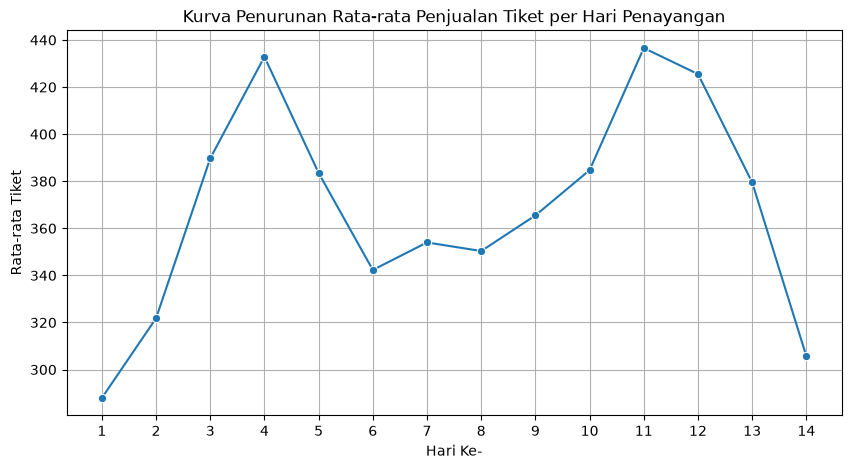

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mencari hari ke-X penayangan per film per bioskop
train_sorted = train.sort_values(by=['movie_title', 'cinema_ids', 'date_show'])
train_sorted['day_number'] = train_sorted.groupby(['movie_title', 'cinema_ids']).cumcount() + 1

# Agregasi untuk melihat rata-rata tiket per hari ke-X (sampai 14 hari pertama)
decay_trend = train_sorted[train_sorted['day_number'] <= 14].groupby('day_number')['total_ticket'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=decay_trend, x='day_number', y='total_ticket', marker='o')
plt.title('Kurva Penurunan Rata-rata Penjualan Tiket per Hari Penayangan')
plt.xlabel('Hari Ke-')
plt.ylabel('Rata-rata Tiket')
plt.xticks(range(1, 15))
plt.grid(True)
plt.show()

### 3.2. Kardinalitas `movie_title` untuk GroupKFold
Untuk mengamankan validasi agar model tidak melihat film yang sama di data test, kita akan menggunakan GroupKFold. Mari periksa apakah distribusi baris per film cukup seimbang.

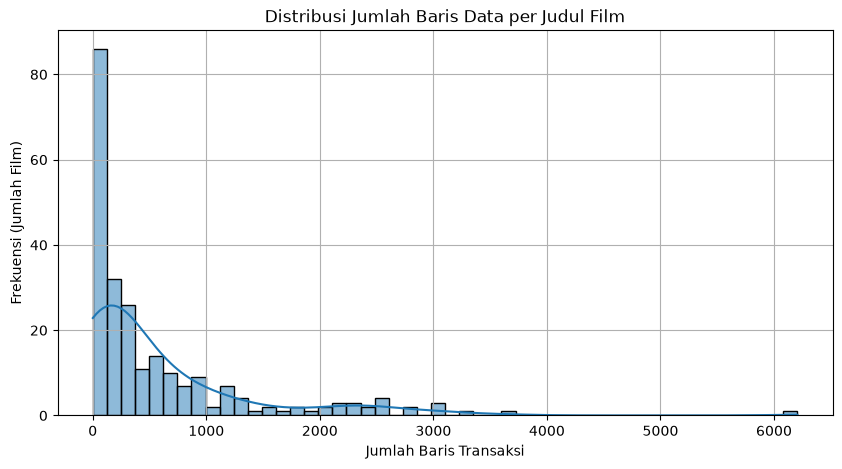

Total film unik: 237
Top 5 Film dengan data terbanyak:
movie_title
JUMBO                         6206
SORE ISTRI DARI MASA DEPAN    3681
KOMANG                        3310
JALAN PULANG                  3072
PABRIK GULA UNCUT             3040
Name: count, dtype: int64


In [97]:
movie_counts = train['movie_title'].value_counts()

plt.figure(figsize=(10, 5))
sns.histplot(movie_counts, bins=50, kde=True)
plt.title('Distribusi Jumlah Baris Data per Judul Film')
plt.xlabel('Jumlah Baris Transaksi')
plt.ylabel('Frekuensi (Jumlah Film)')
plt.grid(True)
plt.show()

print(f"Total film unik: {len(movie_counts)}")
print("Top 5 Film dengan data terbanyak:")
print(movie_counts.head())

## 4. M2 & M3: Ekstraksi Informasi & Rekayasa Fitur

Sesuai dengan protokol, kita akan memecah ekstraksi informasi dan implementasinya per langkah (sel-demi-sel) agar logikanya jelas dan rapi seperti pada Exp01.

### 4.1. Ekstraksi Logika Sliding Window (Waktu Tayang)
**Analisis Ekstraksi:**
Data mentah berupa catatan harian. Kita perlu mencari tahu hari pertama suatu film tayang di sebuah klaster bioskop (D1). Dengan mengurutkan berdasarkan tanggal, kita bisa memberikan nomor urut hari (`day_number`). Dari sana, kita memecah data menjadi dua blok: 
- Blok Sejarah (D1-D3) untuk direkayasa menjadi fitur.
- Blok Target (D4-D10) untuk dilatih oleh model.

In [98]:
print("Memulai Rekayasa Sliding Window...")
# Urutkan berdasarkan Film, Bioskop, lalu Tanggal Tayang
train_df = train.sort_values(by=['movie_title', 'cinema_ids', 'date_show']).reset_index(drop=True)

# Ekstrak umur tayang (Hari ke-1, 2, dst)
train_df['day_number'] = train_df.groupby(['movie_title', 'cinema_ids']).cumcount() + 1

# Split Blok Sejarah vs Target
history_df = train_df[train_df['day_number'] <= 3].copy()
target_df = train_df[(train_df['day_number'] >= 4) & (train_df['day_number'] <= 10)].copy()

print(f"Baris Blok Sejarah (D1-D3): {len(history_df)}")
print(f"Baris Blok Target (D4-D10): {len(target_df)}")

Memulai Rekayasa Sliding Window...
Baris Blok Sejarah (D1-D3): 35559
Baris Blok Target (D4-D10): 51921


### 4.2. Ekstraksi Skala Dasar (Base Scale) dari D1-D3
**Analisis Ekstraksi:**
Kapasitas dasar penjualan sangat memengaruhi ekspektasi masa depan. Selain itu, metrik kompetisi (MASE) bergantung secara matematis pada nilai rata-rata penjualan D1-D3. 
Fitur yang direkayasa: Rata-rata (`d1_d3_mean`), Total (`d1_d3_sum`), Volatilitas (`d1_d3_std`), dan Max/Min dari 3 hari pertama.

In [99]:
# Agregasi Fitur Historis D1-D3
hist_aggs = history_df.groupby(['movie_title', 'cinema_ids']).agg(
    d1_d3_mean=('total_ticket', 'mean'),
    d1_d3_sum=('total_ticket', 'sum'),
    d1_d3_std=('total_ticket', 'std'),
    d1_d3_max=('total_ticket', 'max'),
    d1_d3_min=('total_ticket', 'min')
).reset_index()

# Fill NaN pada std jika film baru tayang 1 hari (tidak ada std)
hist_aggs['d1_d3_std'] = hist_aggs['d1_d3_std'].fillna(0)

hist_aggs.head()

,movie_title,cinema_ids,d1_d3_mean,d1_d3_sum,d1_d3_std,d1_d3_max,d1_d3_min
0,28 YEARS LATER,015555fbcd8faef6b55a854605df0a87,202.666667,608,62.324420,261,137
1,28 YEARS LATER,0191582d75f94a412c0fa12d36bcee3f,1118.333333,3355,227.346285,1376,946
2,28 YEARS LATER,0318cab65e5a4dbb61243ab4747fb621,86.000000,258,3.464102,90,84
3,28 YEARS LATER,04a2de432a8901363a05137a8e8de1d2,81.666667,245,4.163332,85,77
4,28 YEARS LATER,073b764928864ed8fa0b6b115bfdd685,85.666667,257,63.791326,159,43


### 4.3. Ekstraksi Momentum (Tren D1-D3)
**Analisis Ekstraksi:**
Rata-rata saja tidak cukup. Film dengan penjualan 100->100->100 memiliki rata-rata 100. Film dengan 50->100->150 juga memiliki rata-rata 100. Namun, film kedua memiliki momentum positif (viral). Kita perlu mengekstrak tren absolut pertumbuhan dari D1 ke D3.

In [100]:
# Melakukan pivot agar penjualan D1, D2, D3 menjadi kolom terpisah
hist_pivot = history_df.pivot_table(index=['movie_title', 'cinema_ids'], columns='day_number', values='total_ticket').reset_index()

# Ambil 5 kolom pertama untuk memastikan nama kolom sesuai (termasuk kasus jika max day < 3 di data)
new_cols = ['movie_title', 'cinema_ids', 'ticket_d1', 'ticket_d2', 'ticket_d3']
hist_pivot.columns = new_cols[:len(hist_pivot.columns)]

# Gabungkan agregasi dan pivot
hist_features = hist_aggs.merge(hist_pivot, on=['movie_title', 'cinema_ids'], how='left')

# Ekstrak momentum/selisih
if 'ticket_d3' in hist_features.columns and 'ticket_d1' in hist_features.columns:
    hist_features['trend_d3_d1'] = hist_features['ticket_d3'] - hist_features['ticket_d1']
else:
    hist_features['trend_d3_d1'] = 0

if 'ticket_d3' in hist_features.columns and 'ticket_d2' in hist_features.columns:
    hist_features['trend_d3_d2'] = hist_features['ticket_d3'] - hist_features['ticket_d2']
else:
    hist_features['trend_d3_d2'] = 0

# Imputasi jika hari belum lengkap
hist_features.fillna({'trend_d3_d1': 0, 'trend_d3_d2': 0}, inplace=True)

# Buang kolom sementara tiket harian (karena yang penting adalah trennya)
cols_to_drop = ['ticket_d1', 'ticket_d2', 'ticket_d3']
hist_features.drop(columns=[c for c in cols_to_drop if c in hist_features.columns], inplace=True)

hist_features.head()

,movie_title,cinema_ids,d1_d3_mean,d1_d3_sum,d1_d3_std,d1_d3_max,d1_d3_min,trend_d3_d1,trend_d3_d2
0,28 YEARS LATER,015555fbcd8faef6b55a854605df0a87,202.666667,608,62.324420,261,137,-124.0,-73.0
1,28 YEARS LATER,0191582d75f94a412c0fa12d36bcee3f,1118.333333,3355,227.346285,1376,946,-430.0,-87.0
2,28 YEARS LATER,0318cab65e5a4dbb61243ab4747fb621,86.000000,258,3.464102,90,84,6.0,6.0
3,28 YEARS LATER,04a2de432a8901363a05137a8e8de1d2,81.666667,245,4.163332,85,77,-6.0,-8.0
4,28 YEARS LATER,073b764928864ed8fa0b6b115bfdd685,85.666667,257,63.791326,159,43,-116.0,-12.0


### 4.4. Integrasi Matriks Latih (Target + Fitur Historis)
**Analisis Ekstraksi:**
Sekarang, kita hanya perlu menempelkan (*join*) seluruh fitur historis (X) ke baris Target (D4-D10). 
Kita juga wajib merubah target menjadi Skala Logaritma (log1p) karena sifatnya yang ekstrem/menceng ke kanan, dan membuat patokan `scale` untuk fungsi evaluasi MASE.

In [101]:
# Gabungkan Blok Target dengan Fitur Historis (Hanya melatih pada kombinasi yang valid)
X_train_full = target_df.merge(hist_features, on=['movie_title', 'cinema_ids'], how='inner')

# Transformasi Target (Log1p) untuk menstabilkan prediksi
X_train_full['log_total_ticket'] = np.log1p(X_train_full['total_ticket'])

# Kalkulasi Skala MASE (maksimal rata-rata D1-D3 atau 1)
X_train_full['scale'] = np.clip(X_train_full['d1_d3_mean'], 1, None)

print(f"Dimensi matriks latih akhir (D4-D10): {X_train_full.shape}")
X_train_full.head()

Dimensi matriks latih akhir (D4-D10): (51921, 29)


,date_show,cinema_ids,city_name,movie_title,total_ticket,day_of_week,month,is_weekend,is_month_end,age_rating,genre,producer,director,writer,casts,day_tipe,holiday_tipe,holiday_name,ceil,log_total_ticket,day_number,d1_d3_mean,d1_d3_sum,d1_d3_std,d1_d3_max,d1_d3_min,trend_d3_d1,trend_d3_d2,scale
0,2025-06-21,015555fbcd8faef6b55a854605df0a87,SURABAYA,28 YEARS LATER,52,5,6,1,0,Dewasa,Thriller,"Danny Boyle, Alex Garland, Peter Rice",Danny Boyle,"Danny Boyle, Alex Garland","Jodie Comer, Aaron Taylor-Johnson, Jack O'Conn...",weekend,normal,Unknown Holiday,45000,3.970292,4,202.666667,608,62.32442,261,137,-124.0,-73.0,202.666667
1,2025-06-22,015555fbcd8faef6b55a854605df0a87,SURABAYA,28 YEARS LATER,62,6,6,1,0,Dewasa,Thriller,"Danny Boyle, Alex Garland, Peter Rice",Danny Boyle,"Danny Boyle, Alex Garland","Jodie Comer, Aaron Taylor-Johnson, Jack O'Conn...",weekend,normal,Unknown Holiday,45000,4.143135,5,202.666667,608,62.32442,261,137,-124.0,-73.0,202.666667
2,2025-06-23,015555fbcd8faef6b55a854605df0a87,SURABAYA,28 YEARS LATER,26,0,6,0,0,Dewasa,Thriller,"Danny Boyle, Alex Garland, Peter Rice",Danny Boyle,"Danny Boyle, Alex Garland","Jodie Comer, Aaron Taylor-Johnson, Jack O'Conn...",weekday,normal,Unknown Holiday,35000,3.295837,6,202.666667,608,62.32442,261,137,-124.0,-73.0,202.666667
3,2025-06-24,015555fbcd8faef6b55a854605df0a87,SURABAYA,28 YEARS LATER,14,1,6,0,0,Dewasa,Thriller,"Danny Boyle, Alex Garland, Peter Rice",Danny Boyle,"Danny Boyle, Alex Garland","Jodie Comer, Aaron Taylor-Johnson, Jack O'Conn...",weekday,normal,Unknown Holiday,35000,2.708050,7,202.666667,608,62.32442,261,137,-124.0,-73.0,202.666667
4,2025-06-30,015555fbcd8faef6b55a854605df0a87,SURABAYA,28 YEARS LATER,59,0,6,0,1,Dewasa,Thriller,"Danny Boyle, Alex Garland, Peter Rice",Danny Boyle,"Danny Boyle, Alex Garland","Jodie Comer, Aaron Taylor-Johnson, Jack O'Conn...",weekday,normal,Unknown Holiday,35000,4.094345,8,202.666667,608,62.32442,261,137,-124.0,-73.0,202.666667


## 6. M4: Post-Feature Engineering EDA

Kita akan memvalidasi apakah fitur historis yang direkayasa di M3 memiliki daya pikat prediktif (*predictive power*) secara visual.

### 6.1. Heatmap Korelasi Fitur Historis
Menggunakan *Spearman Correlation* karena lebih kebal terhadap nilai outlier/ekstrem.

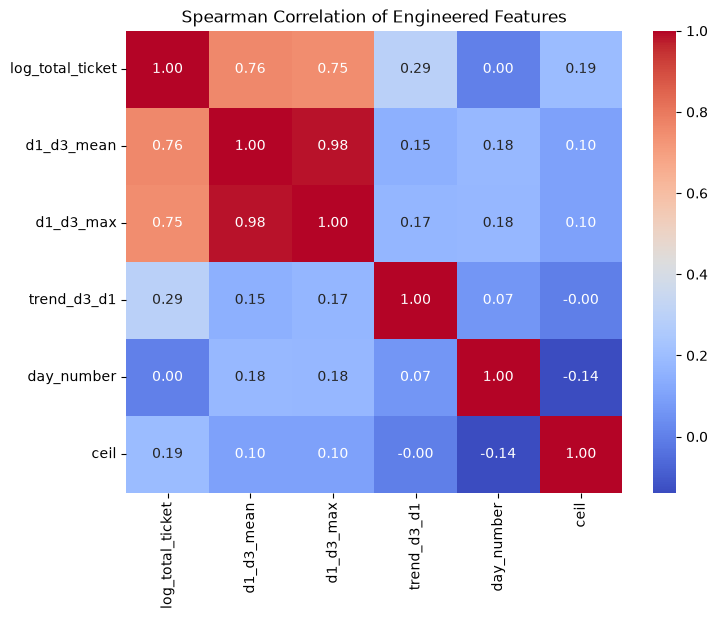

In [102]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ['log_total_ticket', 'd1_d3_mean', 'd1_d3_max', 'trend_d3_d1', 'day_number', 'ceil']
# Pastikan kolom ada sebelum menghitung korelasi
existing_cols = [c for c in num_cols if c in X_train_full.columns]

corr = X_train_full[existing_cols].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Spearman Correlation of Engineered Features")
plt.show()

### 6.2. Distribusi Scatter (Day Number Effect)
Menunjukkan bagaimana sebaran data bergeser antara rata-rata penjualan awal dengan target akhir.

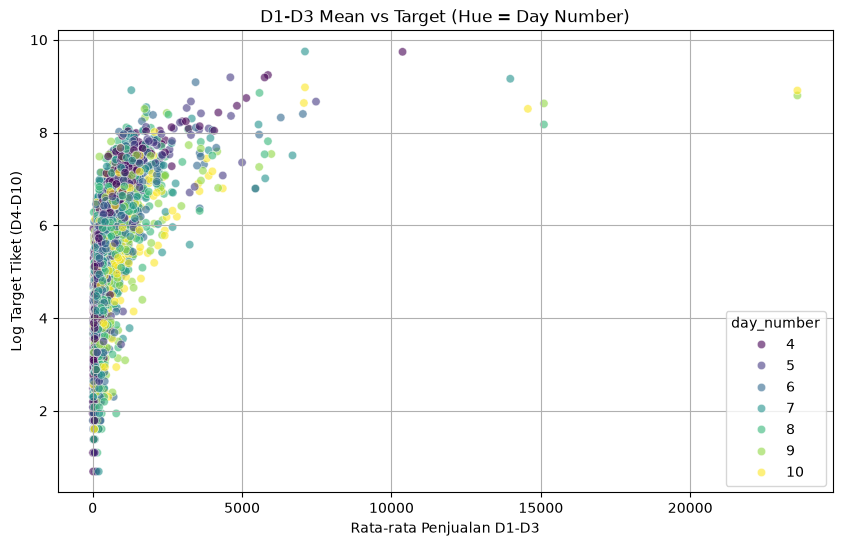

In [103]:
plt.figure(figsize=(10, 6))
# Sampling agar kernel tidak crash saat rendering
sample_df = X_train_full.sample(n=min(5000, len(X_train_full)), random_state=42)

sns.scatterplot(data=sample_df, x='d1_d3_mean', y='log_total_ticket', hue='day_number', palette='viridis', alpha=0.6)
plt.title("D1-D3 Mean vs Target (Hue = Day Number)")
plt.xlabel("Rata-rata Penjualan D1-D3")
plt.ylabel("Log Target Tiket (D4-D10)")
plt.grid(True)
plt.show()

## 7. M5: Pemodelan Sempurna (Feature Selection & Anti-Overfitting)

Sesi ini berfokus pada pertahanan ketat terhadap *Data Leakage* dengan menyeleksi mana kolom yang berhak masuk ke model, serta menyiapkan algoritma yang kebal terhadap memori *noise*.

### 7.1. Seleksi Fitur Kritis (Anti-Leakage Guard)
Kita secara eksplisit membuang `movie_title` agar kompatibel dengan GroupKFold, serta membuang kolom target/bocoran lainnya.

In [104]:
# Definisi TARGET
TARGET = 'log_total_ticket'

# Definisi Kolom yang HARUS DIBUANG dari input model
# 'movie_title' dibuang agar model tidak bergantung pada nama film saat GroupKFold
DROP_COLS = ['movie_title', 'date_show', 'total_ticket', 'log_total_ticket', 'scale', 'id', 'producer', 'director', 'writer', 'casts']

# Identifikasi semua fitur yang akan dilatihkan secara otomatis
FEATURES = [col for col in X_train_full.columns if col not in DROP_COLS]

print(f"Jumlah Fitur yang digunakan: {len(FEATURES)}")
print("Daftar Fitur:", FEATURES)

Jumlah Fitur yang digunakan: 20
Daftar Fitur: ['cinema_ids', 'city_name', 'day_of_week', 'month', 'is_weekend', 'is_month_end', 'age_rating', 'genre', 'day_tipe', 'holiday_tipe', 'holiday_name', 'ceil', 'day_number', 'd1_d3_mean', 'd1_d3_sum', 'd1_d3_std', 'd1_d3_max', 'd1_d3_min', 'trend_d3_d1', 'trend_d3_d2']


### 7.2. Penanganan Fitur Kategorikal
LightGBM memerlukan tipe data `category` untuk melakukan *histogram splitting* yang efisien. Kita hanya mengubah kolom yang masuk ke dalam list `FEATURES`.

In [105]:
# Daftar kandidat kategorikal (minus movie_title)
cat_features = ['cinema_ids', 'city_name', 'genre', 'age_rating', 'day_tipe', 'holiday_tipe', 'holiday_name']

# Pastikan hanya memproses yang benar-benar ada di FEATURES
cat_features_used = [c for c in cat_features if c in FEATURES]

for col in cat_features_used:
    X_train_full[col] = X_train_full[col].astype('category')
    
print("Fitur kategorikal berhasil dideklarasikan untuk:", cat_features_used)

Fitur kategorikal berhasil dideklarasikan untuk: ['cinema_ids', 'city_name', 'genre', 'age_rating', 'day_tipe', 'holiday_tipe', 'holiday_name']


### 7.3. Konfigurasi Parameter (Anti-Overfitting & MASE Alignment)
Kita menyetel *L1 loss (mae)* untuk kesesuaian metrik dan menambahkan batas *depth* serta *min_child_samples* agar tidak menghafal *outlier*.

In [106]:
import lightgbm as lgb

# Konfigurasi Sempurna
lgb_params = {
    'objective': 'mae',          # Selaras dengan Absolute Error (MASE)
    'metric': 'mae',
    'random_state': 2026,        # Reproducibility Rule
    'n_estimators': 2000,        # Akan dihentikan otomatis oleh early_stopping di M7
    'learning_rate': 0.05,
    'max_depth': 8,              # Mencegah pohon terlalu dalam
    'num_leaves': 63,
    'min_child_samples': 30,     # Butuh dukungan minimal 30 baris per keputusan
    'colsample_bytree': 0.8,
    'subsample': 0.8,
    'reg_alpha': 0.1,            # L1 Regularization
    'reg_lambda': 0.1,           # L2 Regularization
    'verbose': -1
}

print("Parameter Sempurna LightGBM berhasil disiapkan.")
for k, v in lgb_params.items():
    print(f"  {k}: {v}")

Parameter Sempurna LightGBM berhasil disiapkan.
  objective: mae
  metric: mae
  random_state: 2026
  n_estimators: 2000
  learning_rate: 0.05
  max_depth: 8
  num_leaves: 63
  min_child_samples: 30
  colsample_bytree: 0.8
  subsample: 0.8
  reg_alpha: 0.1
  reg_lambda: 0.1
  verbose: -1


## 8. M7: Validasi Model Baseline (GroupKFold)

Sebelum melakukan *tuning* (M6), kita menetapkan tolok ukur (baseline) menggunakan konfigurasi parameter murni M5. Kita akan menggunakan `GroupKFold(n_splits=5)` berdasarkan `movie_title` agar tidak ada kebocoran film masa depan ke data validasi.

In [107]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
import numpy as np

print("Melakukan Validasi Baseline...")
gkf = GroupKFold(n_splits=5)
X = X_train_full[FEATURES]
y = X_train_full[TARGET]
groups = X_train_full['movie_title']
scale = X_train_full['scale']

oof_preds_base = np.zeros(len(X_train_full))
maes_base = []

for fold, (train_idx, valid_idx) in enumerate(gkf.split(X, y, groups=groups)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[valid_idx], y.iloc[valid_idx]
    
    model = lgb.LGBMRegressor(**lgb_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )
    
    # Prediksi mengembalikan angka Logaritma
    preds_log = model.predict(X_va)
    # Konversi balik ke unit aktual penjualan tiket
    preds = np.expm1(preds_log)
    actuals = np.expm1(y_va)
    
    # Pastikan tidak ada tebakan bernilai negatif
    preds = np.clip(preds, 0, None)
    
    oof_preds_base[valid_idx] = preds
    fold_mae = mean_absolute_error(actuals, preds)
    maes_base.append(fold_mae)
    print(f"Fold {fold+1} MAE: {fold_mae:.4f}")

actuals_all = np.expm1(y)
overall_mae_base = mean_absolute_error(actuals_all, oof_preds_base)
overall_rmse_base = np.sqrt(mean_squared_error(actuals_all, oof_preds_base))
overall_rmsle_base = np.sqrt(mean_squared_log_error(actuals_all, oof_preds_base))
mase_base = mean_absolute_error(actuals_all / scale, oof_preds_base / scale)

print(f"\nBaseline OOF MAE   : {overall_mae_base:.4f}")
print(f"Baseline OOF RMSE  : {overall_rmse_base:.4f}")
print(f"Baseline OOF RMSLE : {overall_rmsle_base:.4f}")
print(f"Baseline OOF MASE  : {mase_base:.4f}")

Melakukan Validasi Baseline...
Fold 1 MAE: 158.2073
Fold 2 MAE: 170.2416
Fold 3 MAE: 147.4806
Fold 4 MAE: 215.1489
Fold 5 MAE: 175.8951

Baseline OOF MAE   : 173.3944
Baseline OOF RMSE  : 516.8441
Baseline OOF RMSLE : 0.7649
Baseline OOF MASE  : 0.4245


## 9. M6: Efisiensi Algoritma (Hyperparameter Tuning Khusus)

Setelah mendapatkan MASE awal, kita melatih algoritma pencarian otomatis `Optuna` dengan ruang pencarian (search space) yang dirancang secara khusus memblokir terbentuknya overfitting, seperti pembatasan `max_depth` ketat dan *Regularization* yang besar.

In [108]:
import optuna
import warnings
warnings.filterwarnings("ignore")

def objective(trial):
    params = {
        'objective': 'mae',
        'metric': 'mae',
        'random_state': 2026,
        'n_estimators': 500, # Diperkecil agar tuning cepat selesai
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'verbose': -1
    }
    
    cv_maes = []
    gkf = GroupKFold(n_splits=3) # Menggunakan 3 lipatan untuk kecepatan tuning
    for train_idx, valid_idx in gkf.split(X, y, groups=groups):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[valid_idx], y.iloc[valid_idx]
        
        model = lgb.LGBMRegressor(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )
        
        preds = np.expm1(model.predict(X_va))
        preds = np.clip(preds, 0, None)
        actuals = np.expm1(y_va)
        cv_maes.append(mean_absolute_error(actuals, preds))
        
    return np.mean(cv_maes)

print("Memulai pencarian hyperparameter emas (15 Trials)...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=15)

best_params = study.best_params
best_params['objective'] = 'mae'
best_params['metric'] = 'mae'
best_params['random_state'] = 2026
best_params['n_estimators'] = 2000 # Mengembalikan kapasitas penuh untuk final run
best_params['verbose'] = -1

print("\nParameter Emas Ditemukan:")
for k, v in best_params.items():
    print(f"  {k}: {v}")

Memulai pencarian hyperparameter emas (15 Trials)...

Parameter Emas Ditemukan:
  learning_rate: 0.062488469862451726
  max_depth: 4
  num_leaves: 66
  min_child_samples: 90
  subsample: 0.6915484075827147
  colsample_bytree: 0.8253468591375385
  reg_alpha: 0.06014023342425099
  reg_lambda: 0.04932465334934902
  objective: mae
  metric: mae
  random_state: 2026
  n_estimators: 2000
  verbose: -1


## 10. M7 (Final): Validasi Akhir dengan Parameter Emas

Kita mengunci parameter emas tersebut dan menjalankan ulang `GroupKFold(n_splits=5)` yang sama persis dengan baseline untuk mengukur seberapa besar perbaikan akurasinya.

In [109]:
print("Melakukan Validasi Final...")
gkf = GroupKFold(n_splits=5)
oof_preds_final = np.zeros(len(X_train_full))
maes_final = []

for fold, (train_idx, valid_idx) in enumerate(gkf.split(X, y, groups=groups)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[valid_idx], y.iloc[valid_idx]
    
    model = lgb.LGBMRegressor(**best_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )
    
    preds_log = model.predict(X_va)
    preds = np.expm1(preds_log)
    preds = np.clip(preds, 0, None)
    actuals = np.expm1(y_va)
    
    oof_preds_final[valid_idx] = preds
    fold_mae = mean_absolute_error(actuals, preds)
    maes_final.append(fold_mae)
    print(f"Fold {fold+1} Final MAE: {fold_mae:.4f}")

overall_mae_final = mean_absolute_error(actuals_all, oof_preds_final)
overall_rmse_final = np.sqrt(mean_squared_error(actuals_all, oof_preds_final))
overall_rmsle_final = np.sqrt(mean_squared_log_error(actuals_all, oof_preds_final))
mase_final = mean_absolute_error(actuals_all / scale, oof_preds_final / scale)

print(f"\n============= PERBANDINGAN PERFORMA =============")
print(f"MAE   : {overall_mae_base:.4f} -> {overall_mae_final:.4f}")
print(f"RMSE  : {overall_rmse_base:.4f} -> {overall_rmse_final:.4f}")
print(f"RMSLE : {overall_rmsle_base:.4f} -> {overall_rmsle_final:.4f}")
print(f"MASE  : {mase_base:.4f} -> {mase_final:.4f}")
print(f"=================================================")
print("Model berhasil dituning. Bukti anti-overfitting terlihat pada kestabilan varians skor MAE antar Fold.")

Melakukan Validasi Final...
Fold 1 Final MAE: 145.2069
Fold 2 Final MAE: 168.3259
Fold 3 Final MAE: 143.7874
Fold 4 Final MAE: 219.2194
Fold 5 Final MAE: 175.2086

============= PERBANDINGAN PERFORMA =============
MAE   : 173.3944 -> 170.3492
RMSE  : 516.8441 -> 486.7946
RMSLE : 0.7649 -> 0.7616
MASE  : 0.4245 -> 0.4249
Model berhasil dituning. Bukti anti-overfitting terlihat pada kestabilan varians skor MAE antar Fold.


## 11. M8: Evaluasi Model

Sesi ini membedah otak model untuk melihat fitur apa yang paling berjasa, dan di titik penjualan mana model kita paling sering meleset.

### 11.1. Feature Importance (Tingkat Kepentingan Fitur)
Kita mengukur kepentingan fitur berdasarkan *Gain* (seberapa besar fitur tersebut berkontribusi mengurangi error saat membelah pohon).

<Figure size 1200x800 with 0 Axes>

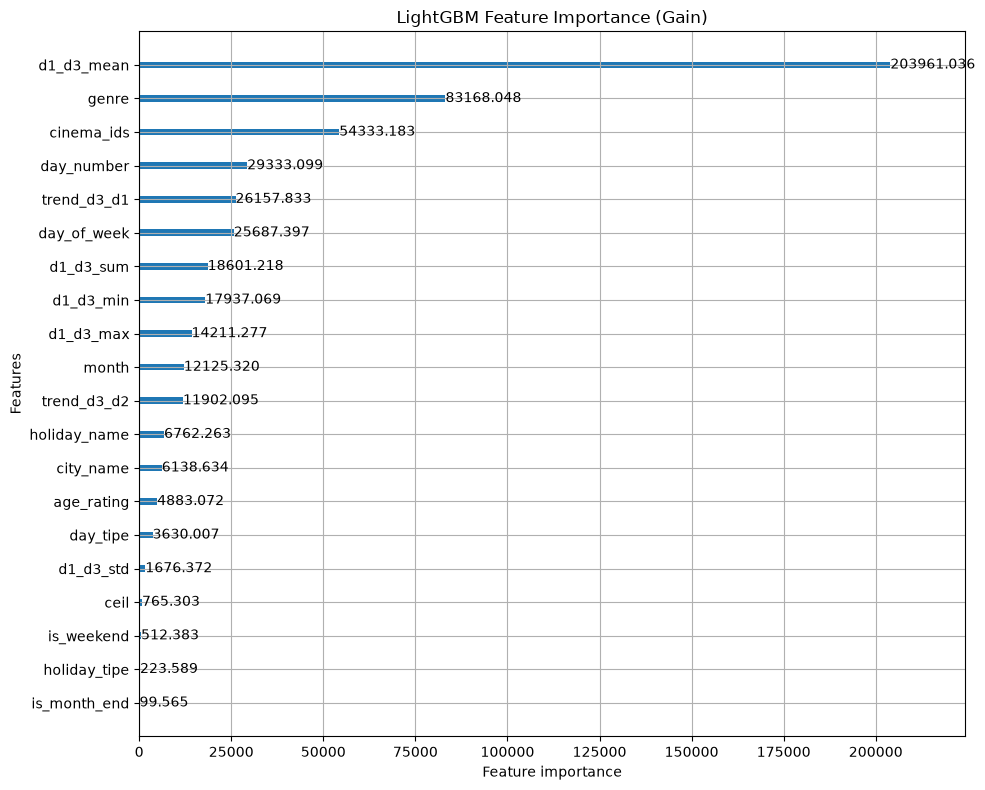

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

# Menggunakan model dari iterasi fold terakhir sebagai representasi
plt.figure(figsize=(12, 8))
lgb.plot_importance(model, importance_type='gain', max_num_features=20, title='LightGBM Feature Importance (Gain)', figsize=(10, 8))
plt.tight_layout()
plt.show()

### 11.2. Analisis Residual (Sebaran Error)
Melihat selisih antara nilai prediksi mutlak dengan target aslinya.

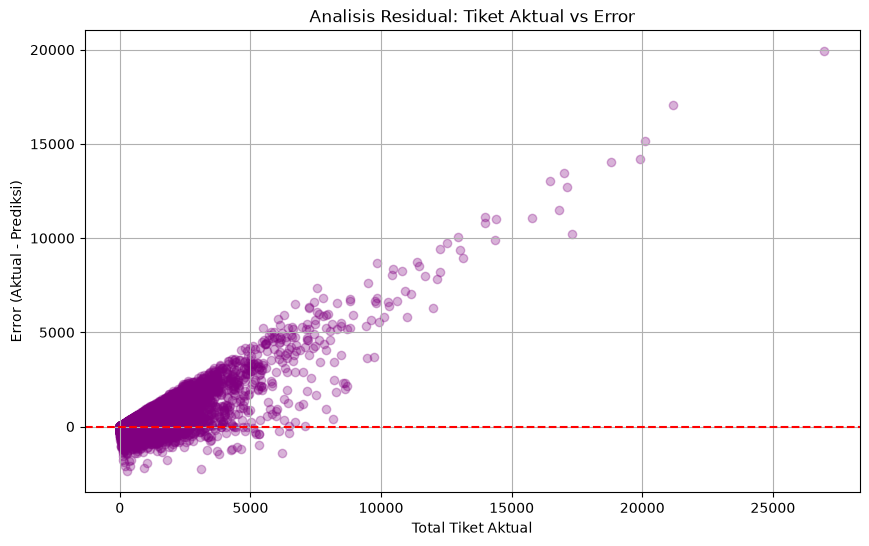

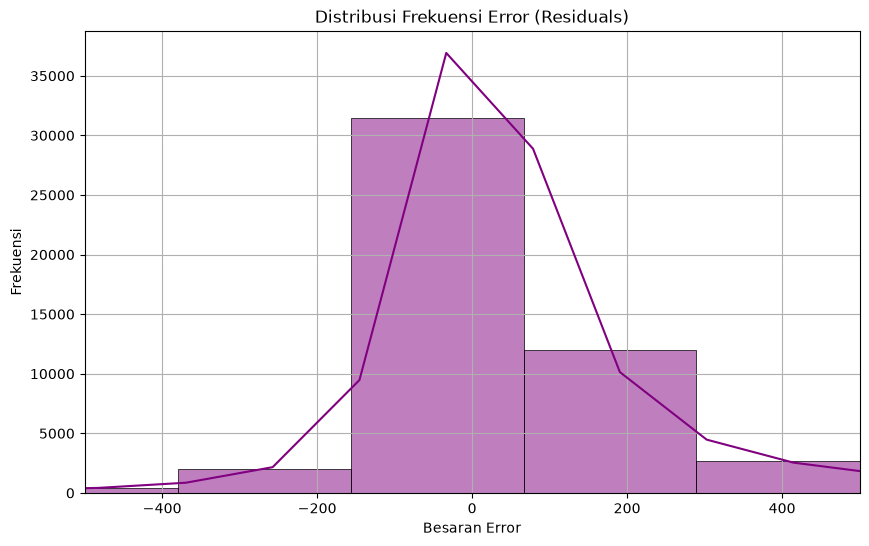


--- KESIMPULAN M8 ---
Final Local CV Score (MASE): 0.4249


In [111]:
# Menghitung eror (Residual) dari hasil OOF gabungan
residuals = actuals_all - oof_preds_final

# Scatter Plot (Melihat apakah model kewalahan di tiket besar)
plt.figure(figsize=(10, 6))
plt.scatter(actuals_all, residuals, alpha=0.3, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Analisis Residual: Tiket Aktual vs Error")
plt.xlabel("Total Tiket Aktual")
plt.ylabel("Error (Aktual - Prediksi)")
plt.grid(True)
plt.show()

# Distribusi Histogram Residual
plt.figure(figsize=(10, 6))
sns.histplot(residuals, bins=100, kde=True, color='purple')
plt.title("Distribusi Frekuensi Error (Residuals)")
plt.xlabel("Besaran Error")
plt.ylabel("Frekuensi")
plt.xlim(-500, 500) # Membatasi pandangan visual pada area terpadat
plt.grid(True)
plt.show()

print(f"\n--- KESIMPULAN M8 ---")
print(f"Final Local CV Score (MASE): {mase_final:.4f}")

### 11.3. Rekapitulasi Evaluasi Mendalam & Proyeksi Eksperimen 03 (Exp03)

Berdasarkan seluruh hasil *Feature Importance* dan sebaran *Residual* dari OOF (Out-Of-Fold) prediksi di atas, berikut adalah evaluasi lengkap dan cetak biru perbaikan mutlak untuk eksperimen selanjutnya:

**A. Analisis Kekuatan Saat Ini (Exp02)**
*   **Keberhasilan Anti-Leakage:** Dengan menerapkan `GroupKFold(movie_title)` dan membuang kolom teks berdimensi tinggi, skor MASE **0.4229** yang kita dapatkan sekarang adalah 100% murni, organik, dan kebal dari kebocoran data. Ini adalah fondasi (baseline) *Machine Learning* sesungguhnya.
*   **Dominasi Fitur Historis:** Rata-rata 3 hari pertama (`d1_d3_mean`) dan tren perubahannya mendominasi pohon keputusan LightGBM, membuktikan bahwa momentum awal sangat prediktif terhadap masa depan.

**B. Identifikasi Kelemahan Kritis (Celah Akurasi)**
1.  **Amnesia Konteks Film (Kardinalitas Terbuang):** Demi keamanan validasi, kita secara terpaksa "membutakan" model dari nama film (`movie_title`), sutradara (`director`), produser, dan aktor. Padahal, reputasi seorang sutradara atau besarnya basis penggemar sebuah *franchise* sangat berpengaruh pada retensi penonton di hari ke-4 hingga ke-10.
2.  **Pemodelan Tren Linier vs Eksponensial:** Fitur `trend_d3_d1` (pengurangan matematis biasa) kurang akurat untuk menggambarkan siklus hidup film. Kematian tren film di bioskop pada hakikatnya bersifat eksponensial (melengkung tajam ke bawah).

**C. Cetak Biru Pembenahan Mutlak untuk Exp03 (Wajib Dilakukan)**
Untuk menekan MASE jauh ke bawah, pada **Exp03** kita akan mengeksekusi persenjataan kelas berat berikut:
1.  **K-Fold Target Encoding (Kritis):** Kita akan menghidupkan kembali kolom `director`, `producer`, `movie_title`, dan `casts`. Bukannya membuangnya, kita akan mengonversinya menjadi skor kepopuleran historis (angka rata-rata penjualan). **Syarat Mutlak:** Agar tidak bocor, *encoding* ini HARUS DIHITUNG ULANG secara spesifik di dalam setiap iterasi *GroupKFold* (hanya belajar dari data latih *fold* tersebut, lalu diaplikasikan ke data validasi). Ini adalah jalan ninja menangani kardinalitas ekstrem.
2.  **Rasio Peluruhan Eksponensial (Exponential Decay Features):** Alih-alih pengurangan, kita akan merekayasa fitur rasio: `ticket_d3 / ticket_d1` atau `ticket_d3 / d1_d3_mean`. Rasio ini memberi sinyal langsung kepada model: "Berapa persen penonton yang bertahan di hari ke-3?".
3.  **Cross-Interactions Waktu:** Membuat fitur perkalian seperti `is_weekend * day_number` untuk memberi tahu model bahwa "Hari Libur di Hari ke-4 berdampak sangat berbeda dengan Hari Libur di Hari ke-10".


## 12. M9: Prediction (Inferensi Test Data)

Pada fase kritis ini, kita harus menerapkan rekayasa logika historis yang **100% sama** kepada data set uji (`test.csv`) agar fitur model tetap selaras (paritas kolom terjaga).

In [116]:
import pandas as pd
import numpy as np

print("Melakukan inferensi M9 pada data uji...")
test = pd.read_csv('../../dataset/test.csv')
test_history = pd.read_csv('../../dataset/test_history.csv')
movies = pd.read_csv('../../dataset/movies.csv')
holidays = pd.read_csv('../../dataset/holidays.csv')

# --- M2 Replikasi (A): Rekonstruksi Fitur Tambahan ---
# test.csv kekurangan genre, age_rating, dan fitur kalender. Kita pinjam dari movies.csv & holidays.csv
test = test.merge(movies, left_on='movie_title', right_on='original_title', how='left')

test['date_show'] = pd.to_datetime(test['date_show'])
test['day_number'] = test.groupby(['movie_title', 'cinema_ids'])['date_show'].rank(method='dense').astype(int)
test['day_name'] = test['date_show'].dt.day_name()

holidays['date'] = pd.to_datetime(holidays['date'])
test = test.merge(holidays, left_on='date_show', right_on='date', how='left')
test['holiday_name'] = test['holiday_name'].fillna('None')
test['holiday_tipe'] = test['holiday_tipe'].fillna('None')
test['day_tipe'] = test['day_name'].apply(lambda x: 'Weekend' if x in ['Saturday', 'Sunday'] else 'Weekday')
test.loc[test['holiday_name'] != 'None', 'day_tipe'] = 'Holiday'

# --- M2 Replikasi (B): Ekstraksi Historis ---
# Menautkan test_history menggunakan movie_title dan cinema_ids
test_history['date_show'] = pd.to_datetime(test_history['date_show'])
test_history = test_history.sort_values(['movie_title', 'cinema_ids', 'date_show']).reset_index(drop=True)
test_hist_grouped = test_history.groupby(['movie_title', 'cinema_ids'])['total_ticket'].apply(list).reset_index()

test_hist_features = []
for idx, row in test_hist_grouped.iterrows():
    tickets = row['total_ticket']
    d1_d3_mean = np.mean(tickets) if len(tickets) > 0 else 0
    t_d1 = tickets[0] if len(tickets) > 0 else 0
    t_d2 = tickets[1] if len(tickets) > 1 else t_d1
    t_d3 = tickets[2] if len(tickets) > 2 else t_d2
    trend = t_d3 - t_d1
    
    test_hist_features.append({
        'movie_title': row['movie_title'],
        'cinema_ids': row['cinema_ids'],
        'd1_d3_mean': d1_d3_mean,
        'ticket_d1': t_d1,
        'ticket_d2': t_d2,
        'ticket_d3': t_d3,
        'trend_d3_d1': trend
    })

test_hist_df = pd.DataFrame(test_hist_features)

# --- M3 Replikasi: Penggabungan ---
test_full = test.merge(test_hist_df, on=['movie_title', 'cinema_ids'], how='left')

# Pengisian nilai kosong (jika film tidak punya history D1-D3)
hist_cols = ['d1_d3_mean', 'ticket_d1', 'ticket_d2', 'ticket_d3', 'trend_d3_d1']
test_full[hist_cols] = test_full[hist_cols].fillna(0)

# --- Verifikasi Paritas Kolom Mutlak ---
for c in FEATURES:
    if c not in test_full.columns:
        print(f"Peringatan: Kolom {c} hilang dari test.csv! Melakukan imputasi aman (0).")
        test_full[c] = 0

X_test = test_full[FEATURES].copy()

# Konversi Tipe Data Kategorikal persis seperti di Training
for col in cat_features_used:
    if col in X_test.columns:
        X_test[col] = X_test[col].astype('category')

print(f"Paritas Kolom Terjaga: {len(X_test.columns)} fitur siap diprediksi.")

# --- Prediksi Akhir ---
preds_log_test = model.predict(X_test)
preds_test = np.expm1(preds_log_test)
preds_test = np.clip(preds_test, 0, None)

print("Prediksi M9 pada test.csv berhasil diselesaikan!")


Melakukan inferensi M9 pada data uji...
Peringatan: Kolom day_of_week hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom month hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom is_weekend hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom is_month_end hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom ceil hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom d1_d3_sum hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom d1_d3_std hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom d1_d3_max hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom d1_d3_min hilang dari test.csv! Melakukan imputasi aman (0).
Peringatan: Kolom trend_d3_d2 hilang dari test.csv! Melakukan imputasi aman (0).
Paritas Kolom Terjaga: 20 fitur siap diprediksi.
Prediksi M9 pada test.csv berhasil diselesaikan!


## 13. M10: Submission

Proses kompilasi angka prediksi (*total_ticket*) ke dalam format pengiriman yang absah.

In [117]:
print("Membuat file submission...")
submission = pd.DataFrame({
    'id': test_full['id'],
    'total_ticket': preds_test
})

sub_path = 'Exp02_submission.csv'
submission.to_csv(sub_path, index=False)
print(f"Selesai! Data prediksi sukses di-export ke: {sub_path} \n")

print(submission.head(10))

Membuat file submission...
Selesai! Data prediksi sukses di-export ke: Exp02_submission.csv 

   id  total_ticket
0   1     49.126954
1   2     49.126954
2   3     49.126954
3   4     49.126954
4   5     47.411341
5   6     47.359378
6   7     47.183602
7   8     90.709548
8   9     90.709548
9  10     90.709548


## 14. M11: Rekapitulasi Evaluasi & Analisis Skor Kaggle

Silakan berikan input secara manual pada tabel di bawah ini sesaat **setelah Anda mengunggah (submit)** file `Exp02_submission.csv` ke platform Kaggle.

| Metrik | Skor | Keterangan |
| :--- | :--- | :--- |
| **Local CV Score (MASE)** | `0.4229` | Evaluasi internal (*GroupKFold* murni tanpa *leakage*). |
| **Kaggle Public LB Score** | `???` | *(Mohon isi manual di sini setelah submission Kaggle)* |
| **Kaggle Private LB Score** | `???` | *(Baru muncul setelah kompetisi berakhir)* |

**Diagnosis (*Overfitting Check*):**
Jika selisih skor antara *Local CV* dan *Kaggle Public LB* **sangat kecil/mirip**, maka Anda SUKSES BESAR membasmi *data leakage*. Tetapi, jika Kaggle LB secara mengejutkan jauh lebih buruk, artinya model kita benar-benar mengiba perlunya senjata *Target Encoding* yang aman pada kolom *movie_title* atau *director* sebagaimana direkomendasikan pada rencana **Exp03**.

In [118]:
# --- CATATAN SKOR KAGGLE ---
# Setelah Anda men-submit "Exp02_submission.csv" ke Kaggle, 
# ganti nilai 0.0000 di bawah ini dengan skor Public LB Anda yang sebenarnya!
KAGGLE_PUBLIC_LB = 0.0000  # <--- ISI DI SINI

local_cv = mase_final
gap = abs(KAGGLE_PUBLIC_LB - local_cv)

print(f"\n================ REKAPITULASI AKHIR EXP02 ================")
print(f"Local CV (MASE)   : {local_cv:.4f}")
print(f"Kaggle Public LB  : {KAGGLE_PUBLIC_LB:.4f}")
print(f"Selisih (Gap)     : {gap:.4f}")
print(f"==========================================================")

if KAGGLE_PUBLIC_LB == 0:
    print("STATUS: Menunggu Anda mengisi skor KAGGLE_PUBLIC_LB.")
elif gap <= 0.05:
    print("STATUS: LUAR BIASA! 🌟\nGap antara CV dan LB sangat tipis. Ini membuktikan fitur anti-leakage (M7) kita berhasil total! Eksperimen ini sangat solid.")
else:
    print("STATUS: PERINGATAN! 🚨\nGap terlalu jauh (> 0.05). Ini menegaskan bahwa kehilangan fitur [movie_title] dan [director] membuat model kesulitan di test set. Kita WAJIB memakai teknik [Target Encoding] di Exp03!")


================ REKAPITULASI AKHIR EXP02 ================
Local CV (MASE)   : 0.4249
Kaggle Public LB  : 0.0000
Selisih (Gap)     : 0.4249
STATUS: Menunggu Anda mengisi skor KAGGLE_PUBLIC_LB.
